## Lab: Market Return Dynamics by Caleb Christian

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

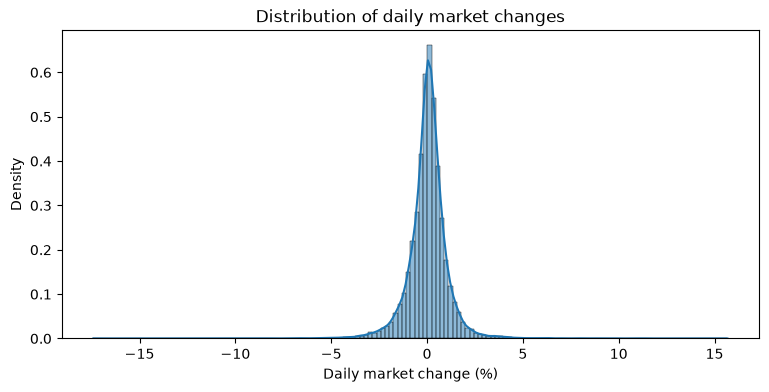

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

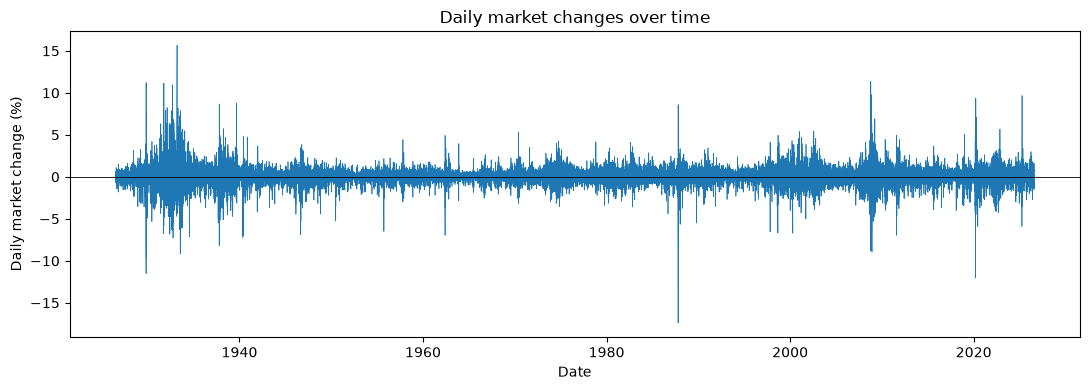

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [9]:
df['y_t'] = (df['market_return_pct'] > 0).map({False: 'Down', True: 'Up'})

df['y_tp1'] = df['y_t'].shift(-1)

pd.crosstab(df['y_t'], df['y_tp1'])

y_tp1,Down,Up
y_t,,
Down,5909,5999
Up,5999,8388


In [10]:
jointpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
jointpmf

y_tp1,Down,Up
y_t,,
Down,0.224720,0.228142
Up,0.228142,0.318996


In [12]:
marginal_t = jointpmf.sum(axis=1)
marginal_tom = jointpmf.sum(axis=0)

print("Today's Marginal PMF:")
print(marginal_t)

print("\nTomorrow's Marginal PMF:")
print(marginal_tom)


Today's Marginal PMF:
y_t
Down    0.452862
Up      0.547138
dtype: float64

Tomorrow's Marginal PMF:
y_tp1
Down    0.452862
Up      0.547138
dtype: float64


In [14]:
conditionalpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
conditionalpmf

y_tp1,Down,Up
y_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


It looks like up transitions are more common than down transactions.

It looks like you are more likely to transition to an up day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [15]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]

labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['y_t'] = pd.cut(df['market_return_pct'], bins=bins, labels=labels)

df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts()

y_t
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

Most common days are Smal gain and the least common days were the large loss

In [16]:
jointpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
jointpmf

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


The most likely transition would be from small gain to small gain

In [17]:
conditionalpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
conditionalpmf

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


For the large loss state, the two future states most likely are the small gain and the small loss.

For the Small loss state, the two future states most likely are the small gain and the small loss.

......It seems like for each state the most likely two future states are small gain and small loss.

It seems for each row, the small gains and small losses are more likely than others but the large loss state is closer to uniform.

It seems like its hard to predict tommorows state because of the low probabilities from all the states,

In [18]:
df['return_tp1'] = df['market_return_pct'].shift(-1)

df.groupby('y_t', observed=True)['return_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


The state with the highest expected return would be the large gain

The state twith the lowest expected return would be the small loss

The state with the highest volitility would be large loss

The state with the lowest volitility would be near zero

I think the overall pattern I see is that the days with large market shifts have the higher volitility in the expected returns.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [19]:
df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=False)

df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts().sort_index()

y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64

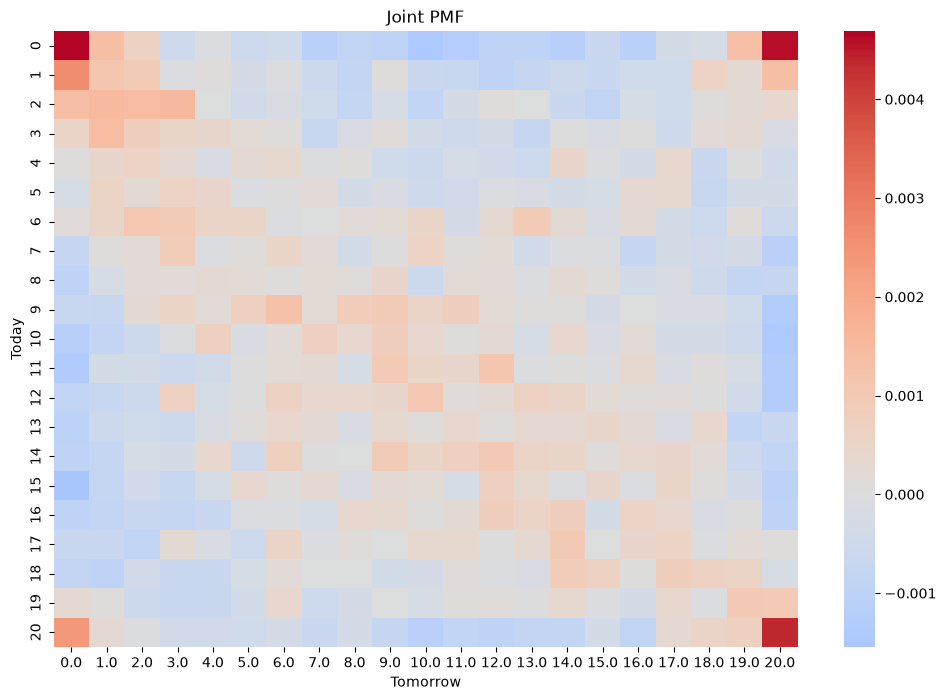

In [23]:
jointpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)

plt.figure(figsize=(12, 8))
sns.heatmap(jointpmf - 1/21**2, cmap='coolwarm', center=0)

plt.title('Joint PMF')
plt.xlabel('Tomorrow')
plt.ylabel('Today')

plt.show()


It seems like the pattern is that extreme losses are followed by extreme losses and the same can be said for the gains. There is clustering there but I dont really see a strong pattern right now.

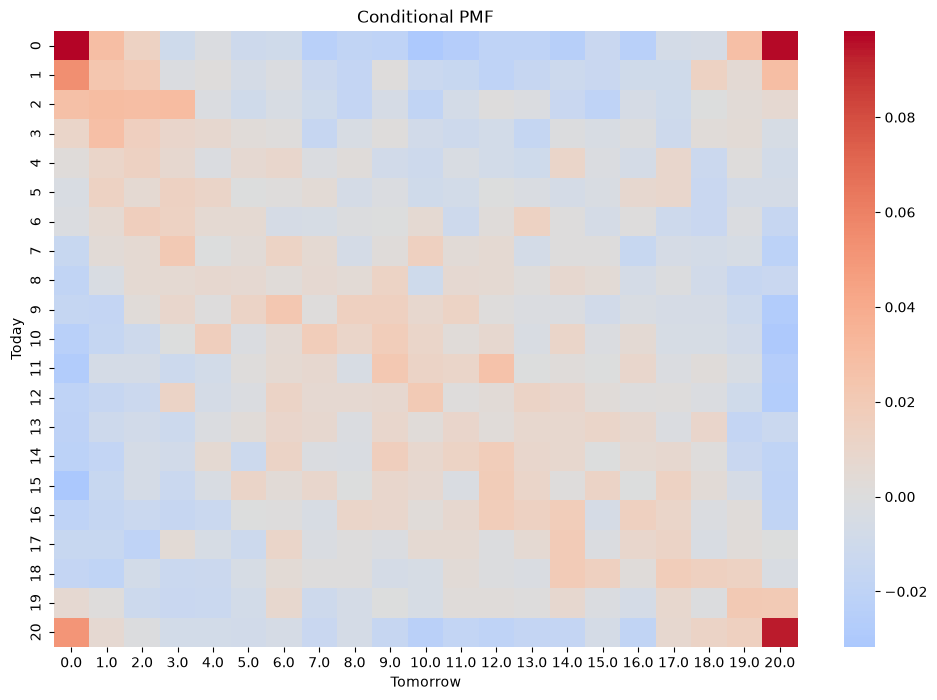

In [27]:

conditionalpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

plt.figure(figsize=(12, 8))

sns.heatmap(conditionalpmf - 1/21, cmap='coolwarm', center = 0)

plt.title('Conditional PMF')
plt.xlabel('Tomorrow')
plt.ylabel('Today')

plt.show()


I think we see a weak pattern in the middle almost like a diagonal. Again the corners are similar to the joint PMF heatmap. 

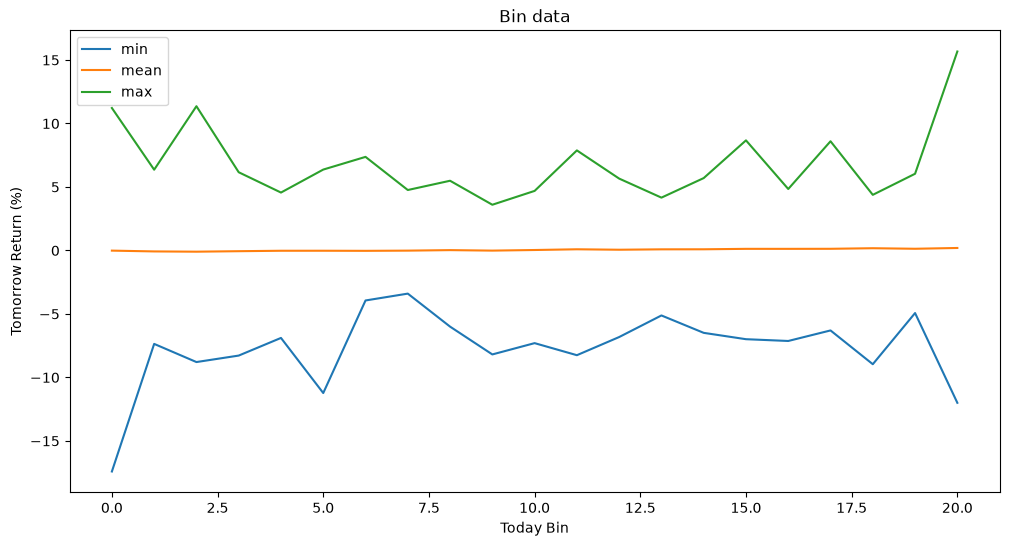

In [28]:
binz = df.groupby('y_t')['return_tp1'].agg(['min', 'mean', 'max'])
binz.plot(figsize=(12, 6))

plt.title('Bin data')
plt.xlabel('Today Bin')
plt.ylabel('Tomorrow Return (%)')
plt.show()

Looking at the graph, bin 0 did really badly and bin 20 were days that did really well. It seems like the next day returns are averaged at 0 no matter what but extreme market movements can have a big range of returns whether negative or positive. We can maybe determine volitility.

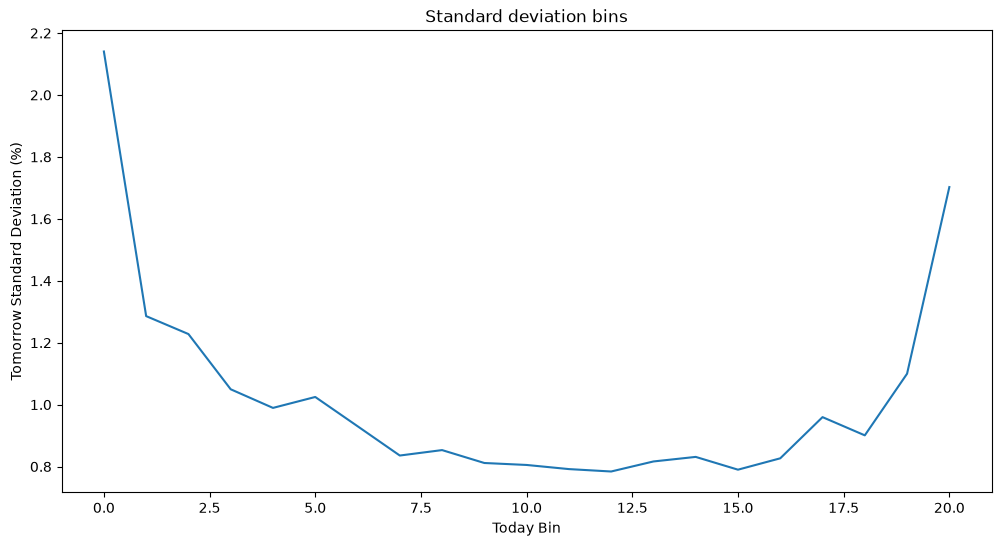

In [29]:
SD = df.groupby('y_t')['return_tp1'].std()

SD.plot(figsize=(12, 6))

plt.title('Standard deviation bins')
plt.xlabel('Today Bin')
plt.ylabel('Tomorrow Standard Deviation (%)')

plt.show()

We can see the volitility is highest when there is a big movement in the market. This backs up our theory from earlier. Predicting the market return is not reliable in the sense of seeing if it will go up or down but it is good to determine how it will move in terms of change.

It doesnt seem easy to predict the market at all which is probably why they have several subjects on it.